# Fruit Classification Dataset
### Projekt PAD
### Viktoriia Oliynyk

# Úvod

V analýze sme použili dataset z adresy: https://www.kaggle.com/datasets/pranavkapratwar/fruit-classification?resource=download

Dataset obsahuje 10000 záznamov o rôznych druhoch ovocia. Najdôležitejšie údaje a premenné, ktoré v analýze použijeme, sú:

- size (cm) – veľkosť plodu v centimetroch
- shape - tvar ovocia (kategória)
- weight (g) – hmotnosť v gramoch
- avg_price (₹) – priemerná cena ovocia
- color – farba ovocia (kategória)
- taste – chuťová kategória (sweet/sour/tangy)
- fruit_name – konkrétny druh ovocia (20 druhov)

V prvom kroku naimportujeme potrebné knižnice. Nimi sú Pandas, Numpy, Matplotlib a Seaborn.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy import stats
from scipy.stats import chi2_contingency

import seaborn as sns

Následne naimportujeme dataset.

In [34]:
print(os.getcwd())
os.chdir("C:\\Users\\Vika\\DataDu\\Oliynyk_project")
df = pd.read_csv("fruit_classification_dataset.csv")

C:\Users\Vika\DataDu\Oliynyk_project


Aby sme mali prehľad, čo dataset obsahuje, vykreslíme časť dataframu.

In [35]:
df.head()

,size (cm),shape,weight (g),avg_price (₹),color,taste,fruit_name
0,25.4,round,3089.2,137.1,green,sweet,watermelon
1,24.6,round,3283.9,163.8,green,sweet,watermelon
2,7.8,round,319.0,91.3,green,sweet,custard apple
3,20.0,oval,1607.0,85.7,orange,sweet,papaya
4,10.2,long,131.5,37.8,yellow,sweet,banana


# Exploračná analýza
## 1. Jednoduché triedenie
### Početnosť farieb (color)

V prvom kroku sa pozrieme na základné rozdelenie kategórií v našom datasete. Keďže premenná color patrí medzi najvýraznejšie vlastnosti ovocia, zobrazíme, ktoré farby sa v dátach vyskytujú najčastejšie. Jednoduchý stĺpcový graf nám rýchlo ukáže, ako sú jednotlivé farby zastúpené.

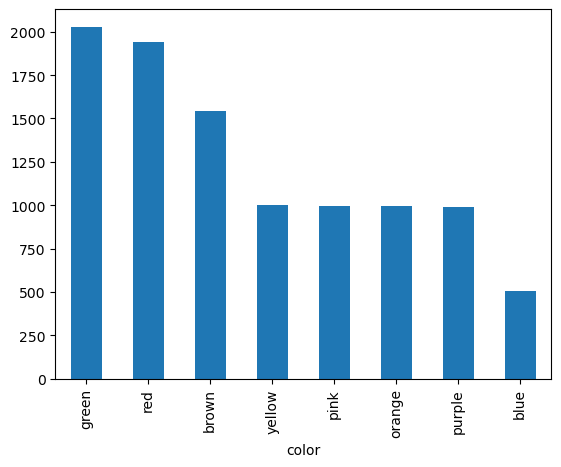

In [36]:
df["color"].value_counts().plot.bar()
plt.show()

Záver: Z grafu vidíme, že najčastejšie farby ovocia sú green a red, ktoré sa v datasete objavujú najviac. Farby brown, yellow, pink, orange a purple majú menej pozorovaní a farba blue je zastúpená najmenej. Rozdelenie farieb je teda nerovnomerné a niektoré farby sa v dátach objavujú výrazne častejšie ako iné.

## 2. Intervalové triedenie 
### Veľkosť ovocia

V ďalšej časti analyzujeme veľkosť ovocia pomocou intervalového triedenia. Premennú size (cm) rozdelíme do niekoľkých logických intervalov, aby sme zistili, v ktorom rozsahu sa veľkosť ovocia najčastejšie vyskytuje. Takéto triedenie nám umožní lepšie pochopiť štruktúru dát a identifikovať dominantné intervaly veľkostí, ako aj prítomnosť veľmi malých alebo veľmi veľkých plodov.

Rozdelili sme premennú size (cm) do intervalov (0–5, 5–10, 10–15, 15+):

In [37]:
pd.cut(df["size (cm)"], bins=[0,5,10,15,100]).value_counts()

size (cm)
(5, 10]      4010
(0, 5]       3461
(15, 100]    1777
(10, 15]      752
Name: count, dtype: int64

<Axes: xlabel='size (cm)'>

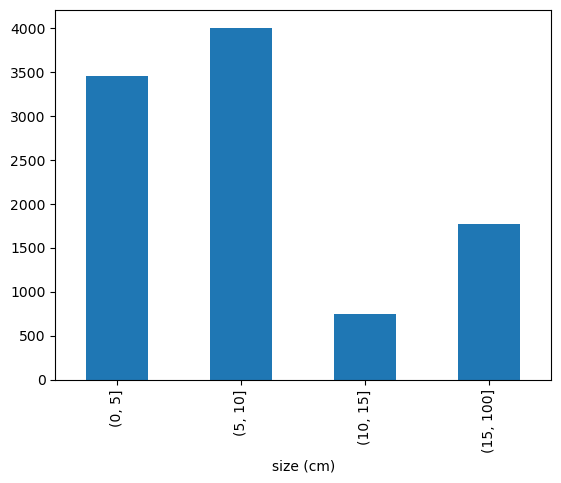

In [38]:
intervals = pd.cut(df["size (cm)"], bins=[0,5,10,15,100])
counts = intervals.value_counts().sort_index()
counts.plot.bar()

Záver: Z grafu vidíme, že najviac ovocia má veľkosť 5–10 cm. To je bežná veľkosť pre ovocie ako apple, orange alebo pear. Menšie plody s veľkosťou 0–5 cm (napr. grape alebo blueberry) tvoria druhú najväčšiu skupinu. Ovocie väčšie ako 15 cm sa objavuje menej často a ide najmä o veľké druhy ako pineapple alebo watermelon. Veľkosti ovocia sú teda nerovnomerné a v datasete sa nachádzajú malé aj veľmi veľké plody.

## 3. Kontingenčná tabuľka
### Taste x Shape

V tomto kroku preskúmame vzťah medzi chuťou ovocia (taste) a jeho tvarom (shape). Pomocou kontingenčnej tabuľky zistíme, ktoré tvary sa najčastejšie spájajú s jednotlivými chuťovými kategóriami. Následne použijeme stacked bar chart, aby sme lepšie videli rozloženie tvarov v rámci každej chuti.

In [39]:
pivot_taste_shape = df.pivot_table(index="taste", columns="shape", values="weight (g)", aggfunc="count", fill_value=0)
pivot_taste_shape

shape,long,oval,round
taste,,,
sour,0,0,481
sweet,502,2956,4046
tangy,0,1526,489


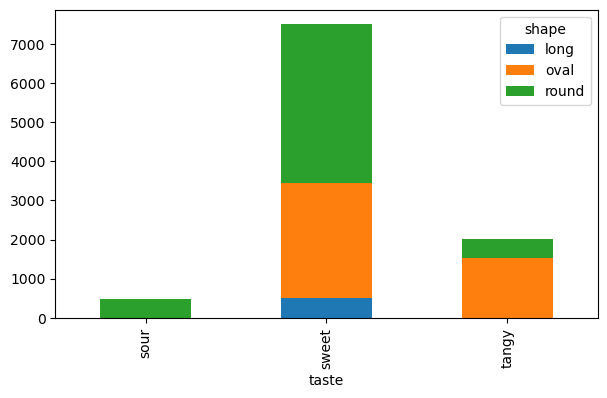

In [40]:
pivot_taste_shape.plot(kind="bar", stacked=True, figsize=(7,4))
plt.show()

Záver: Graf aj tabuľka ukazujú, že medzi tvarom a chuťou ovocia existujú zaujímavé rozdiely. Kategória sweet obsahuje všetky tri tvary, pričom najčastejší je round, nasledovaný oval. Chuť tangy sa spája predovšetkým s tvarom oval, kým sour je v dátach prítomné iba pri tvare round. Tieto rozdiely naznačujú, že tvar ovocia môže súvisieť s jeho chuťovým profilom — napríklad sladké druhy majú najväčšiu variabilitu tvarov, kým iné chute sú viazané na konkrétne tvary.

# Analýza 1
## Inferenčná analýza - testy o stredných hodnotách

V tejto časti sa zameriame na overenie, či existuje štatisticky významný rozdiel v priemernej hmotnosti ovocia medzi dvoma chuťovými skupinami. Konkrétne porovnáme skupinu sladkého (sweet) a kyslého (sour) ovocia.

Keďže premenná taste má v pôvodnom datasete tri kategórie, pre účely t-testu sme sa zamerali iba na dvě jasne oddelené skupiny (sweet vs. sour). Premenná weight (g) je číselná a jednotlivé skupiny sú nezávislé, preto použijeme dvojvýberový t-test pre nezávislé vzorky.

Cieľom analýzy je overiť platnosť nulovej hypotézy:

H0: Priemerná hmotnosť ovocia je rovnaká v skupine sweet aj v skupine sour.

Na overenie použijeme softvér Statistica (v prílohe Oliynyk_projekt/Workbook1).

In [41]:
stat_sweet_sour = pd.read_csv("Sweet_Sour.csv", sep=";") 
#report z workbooku upravený do prehľadnej tabuľky

In [42]:
stat_sweet_sour

,Variable,Mean sweet,Mean sour,t-value,df,p,Valid N sweet,Valid N sour,Std.Dev. Sweet,Std.Dev. Sour,F-ratio Variances,p Variances,"Levene F(1, df)",df Levene,p Levene
0,weight (g),"497,4078092","200,0954262","8,171344866",7983,"0,00",7504,481,"797,9277214","11,699253","4651,690823","0,00","460,7550421",7983,"0,00"


Leveneov test však hovorí, že premenné nemajú rovnaké rozptyly (p < 0,05).

Použijeme preto neparametrickú alternatívu k dvojvýberovému t-test: Mann-Whitneyov U test.

Overujeme H0: Priemerná hmotnosť ovocia je rovnaká v skupine sweet aj v skupine sour.

Na overenie použijeme softvér Statistica (v prílohe Oliynyk_projekt/Workbook2).

In [43]:
stat_mwtest = pd.read_csv("mwtest.csv", sep=";")

In [44]:
stat_mwtest

,Variable,Rank Sum sweet,Rank Sum sour,U,Z,p-value,Z adjusted,p-value.1,Valid N sweet,Valid N sour
0,weight (g),"29897538,5","1986566,5","1738778,5","-1,345271235","0,178538612","-1,345284312","0,178534391",7504,481


Záver: Na základe výsledkov Mann–Whitneyho U testu nezamietame nulovú hypotézu (p > 0,05).
To znamená, že nebol zistený štatisticky významný rozdiel v hmotnosti medzi skupinou sweet a skupinou sour, ak porovnávame tieto dve skupiny pomocou neparametrického testu.

Hmotnosť ovocia sa teda medzi týmito dvoma chuťovými skupinami štatisticky významne nelíši.

# Analýza 2 
## Inferenčná analýza - Korelačná analýza

V tejto časti sa zameriame na overenie, či existuje lineárna závislosť medzi dvoma číselnými premennými z datasetu:

- size (cm) – veľkosť ovocia
- weight (g) – hmotnosť ovocia

Cieľom analýzy je zistiť, či väčšie ovocie má tendenciu mať vyššiu hmotnosť.

Keďže máme veľké množstvo záznamov, môžeme použiť parametrické metódy korelačnej analýzy, konkrétne Pearsonov korelačný koeficient.

Formulujeme nulovú hypotézu
- H0: Medzi veľkosťou ovocia (size) a jeho hmotnosťou (weight) neexistuje žiadna lineárna korelácia.

In [45]:
df[["size (cm)", "weight (g)"]].corr()

,size (cm),weight (g)
size (cm),1.000000,0.918319
weight (g),0.918319,1.000000


Už vo vizualizácii vidíme, že premenné size a weight sa zvyšujú spolu. Korelačný koeficient je r = 0.918, čo predstavuje veľmi silnú pozitívnu koreláciu. To znamená, že väčšie ovocie má takmer vždy aj vyššiu hmotnosť.

Overíme to aj pomocou p hodnoty.

In [46]:
stats.pearsonr(df["size (cm)"], df["weight (g)"])

PearsonRResult(statistic=np.float64(0.9183194288226539), pvalue=np.float64(0.0))

Záver: Keďže p-hodnota je nulová, zamietame hypotézu H0. 

Znamená to, že medzi veľkosťou ovocia (size) a jeho hmotnosťou (weight) existuje štatisticky významná lineárna korelácia.

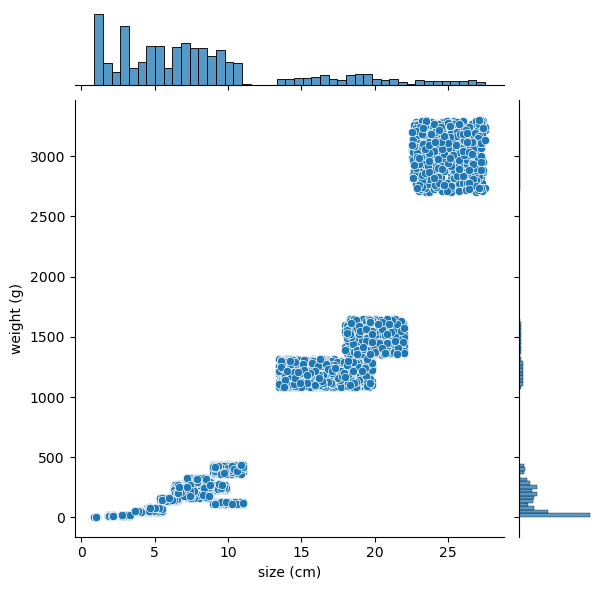

In [47]:
sns.jointplot(data=df, x="size (cm)", y="weight (g)")

Vizualizácia ukazuje výrazný rastúci trend: pri väčších hodnotách premennej size (cm) pozorujeme vyššie hodnoty weight (g). Body vytvárajú niekoľko zhlukov podľa typov ovocia, ale všetky zhluky sú usporiadané pozdĺž vzostupnej línie, čo poukazuje na silnú pozitívnu lineárnu závislosť.

Graf teda vizuálne potvrdzuje výsledky Pearsonovej korelácie.

## Analýza kontingencie

V tejto časti preskúmame, či existuje štatistická závislosť medzi dvoma kategorickými premennými:

- taste — chuť ovocia (sweet, sour, tangy)

- color — farba ovocia (red, green, yellow, blue, purple, orange, brown)

Cieľom je zistiť, či niektoré farby ovocia majú tendenciu byť spojené s určitou chuťou.

Formulujeme nulovú hypotézu

- H0: Medzi premennými taste a color neexistuje žiadna štatistická závislosť.

Použijeme kontingenčnú tabuľku a x² (chi-kvadrát) test nezávislosti.

In [48]:
ct = pd.crosstab(df["taste"], df["color"])
ct

color,blue,brown,green,orange,pink,purple,red,yellow
taste,,,,,,,,
sour,0,0,481,0,0,0,0,0
sweet,503,502,1548,509,998,499,1943,1002
tangy,0,1039,0,487,0,489,0,0


Z kontingenčnej tabuľky je zrejmé, že farby nie sú medzi chuťami rozdelené náhodne.
Niektoré chute sa viažu iba ku konkrétnym farbám (napr. sour → iba green), zatiaľ čo iné sú rozložené veľmi široko (sweet).

Tabuľka preto vizuálne naznačuje prítomnosť štatistickej závislosti medzi taste a color, čo budeme ďalej testovať pomocou x² (chi-kvadrát) testu nezávislosti.

In [49]:
chi2, p, dof, expected = chi2_contingency(ct)
chi2, p, dof

(np.float64(6629.207191625989), np.float64(0.0), 14)

In [50]:
expected

array([[  24.1943,   74.1221,   97.5949,   47.9076,   48.0038,   47.5228,
          93.4583,   48.1962],
       [ 377.4512, 1156.3664, 1522.5616,  747.3984,  748.8992,  741.3952,
        1458.0272,  751.9008],
       [ 101.3545,  310.5115,  408.8435,  200.694 ,  201.097 ,  199.082 ,
         391.5145,  201.903 ]])

Záver: Keďže výsledok x²(14) = 6629.21 a p < 0.001, zamietame hypotézu H0. 

Znamená to, že premenné taste a color sú teda štatisticky významne závislé.

# Záver

Počas analýzy sme preskúmali viaceré vlastnosti ovocia v datasete a zamerali sme sa na ich rozdelenie, vzťahy a štatistické súvislosti.
Exploračná analýza ukázala, že farby ovocia sú rozdelené nerovnomerne — najčastejšie sa vyskytuje zelená a červená farba, zatiaľ čo farba blue je zastúpená najmenej. Pri veľkostiach ovocia sa najviac záznamov nachádza v intervale 5–10 cm, čo zodpovedá bežným druhom ovocia.

V inferenčnej časti sme testovali, či medzi veľkosťou (size) a hmotnosťou (weight) existuje lineárna závislosť. Pearsonova korelácia ukázala veľmi silnú pozitívnu koreláciu (r = 0,918), čo znamená, že väčšie ovocie má vo všeobecnosti vyššiu hmotnosť. Nulová hypotéza bola preto zamietnutá.

Kontingenčná analýza medzi premennými taste a color ukázala, že farby a chute ovocia nie sú rozdelené náhodne. Chi-kvadrát test nezávislosti poskytol extrémne vysokú hodnotu testovacej štatistiky (x² = 6629.21, p < 0.001), čo znamená, že farba ovocia významne súvisí s jeho chuťou. Napríklad chuť sour sa objavovala takmer výlučne pri zelenej farbe, zatiaľ čo sweet bola zastúpená vo väčšine farieb.